#Data Understanding

Dataset ini berasal [Kaggle](https://www.kaggle.com/datasets/sahilprajapati143/retail-analysis-large-dataset), yang merepresentasikan data transaksi ritel. Dataset ini berisi informasi tentang pelanggan, pembelian mereka, produk, dan detail transaksi. Data ini mencakup berbagai atribut seperti ID pelanggan, nama, email, nomor telepon, alamat, kota, negara bagian, kode pos, negara, usia, jenis kelamin, tingkat pendapatan, segmentasi pelanggan, tanggal pembelian terakhir, total pembelian, jumlah uang yang dihabiskan, kategori produk, merek produk, jenis produk, ulasan/umpan balik, metode pengiriman, metode pembayaran, dan status pesanan.

## Data Dictionary
* Transaction_ID: ID transaksi pelanggan
* Customer_ID: ID pelanggan
* Name: nama pelanggan
* Email: email pelanggan dan pengguna
* Phone: nomor telepon pelanggan
* Address: alamat pelanggan
* City: kota pelanggan
* State: negara bagian pelanggan
* Zipcode: kode pos pelanggan
* Country: negara pelanggan
* Age: umur pelanggan
* Gender: jenis kelamin
* Income: pendapatan pelanggan (seperti: tinggi, rendah
* Customer_Segment: segmen pelanggan (seperti: reguler, VIP)
* Date: tanggal pembelian
* Year: tahun pembelian
* Month: bulan pembelian
* Time: waktu pembelian
* Total_Purchases: total berapa banyak unit yang dibeli
* Amount: harga/jumlah yang dihabiskan per unit
* Total_Amount: total jumlah uang yang dihabiskan
* Product_Category: kategori produk
* Product_Brand: merek produk
* Product_Type: tipe produk
* Feedback: ulasan/umpan balik pelanggan
* Shipping_Method: metode pengiriman (seperti: sameday/hari yang sama, dll.)
* Payment_Method: metode pembayaran (seperti: tunai)
* Order_Status: status pesanan (seperti: tertunda, selesai)
* Ratings: penilaian/rating produk
* products: nama produk

# Problem Statement

Perusahaan ritel memiliki total transaksi yang besar di AS menghadapi tantangan dalam mengoptimalkan pertumbuhan pendapatan (revenue) dan retensi pelanggan akibat belum dimanfaatkannya data historis transaksi secara terstruktur. Tanpa pemahaman mendalam mengenai pola segmen pelanggan, frekuensi belanja, kontribusi nilai penjualan, serta tren perilaku transaksi dari waktu ke waktu, perusahaan berisiko salah mengalokasikan anggaran pemasaran, kehilangan pelanggan potensial (churn), dan gagal mempertahankan pelanggan yang paling bernilai (high-value customers).

1. Ketidakjelasan distribusi dan proporsi segmen pelanggan
2. Kurangnya pemahaman terhadap volume dan aktivitas transaksi pelanggan
3. Ketimpangan kontribusi penjualan (revenue contribution) antar segmen
4. Fluktuasi dan perubahan perilaku pelanggan dari waktu ke waktu (trend analysis)


# Business Understanding

Perusahaan ritel memiliki total transaksi yang besar di AS, dan ingin menganalisis transaksinya untuk memahami perilaku pelanggan, seperti berapa banyak uang yang mereka habiskan, seberapa sering mereka berbelanja di perusahaan kami, dan berapa lama jeda waktu mereka untuk kembali berbelanja. Saya akan menganalisisnya menggunakan metode RFM (Recency, Frequency, Monetary). Dengan pemahaman tersebut, perusahaan dapat mengetahui tipe/karakteristik pelanggan mereka, sehingga dapat memberikan promosi, penanganan, manfaat, voucher khusus, dan lain-lain yang pada akhirnya dapat meningkatkan penjualan.

# Analysis Objectives






1. Mengetahui gambaran umum transaksi dan pelanggan
2. Mengidentifikasi proporsi segmentasi pelanggan
3. Menganalisis tingkat loyalitas dan frekuensi belanja
4. Mengevaluasi tren perkembangan segmen dari waktu ke waktu
5. Merumuskan strategi promosi yang tepat sasaran

# Business Questions

1. Berapa total penjualan (total sales), jumlah transaksi, dan jumlah pelanggan yang dimiliki perusahaan?

2. Segmen mana yang paling besar berdasarkan jumlah pelanggannya?

3. Segmen mana yang memiliki frekuensi transaksi tertinggi?

4. Bagaimana tren segmen pelanggan dari waktu ke waktu, apakah ada perubahan dari bulan ke bulan?

5. Jenis promosi apa yang sebaiknya diberikan kepada masing-masing segmen?

In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', None)

# Data Prepocessing

## Read dataset from csv file

In [ ]:
#load data
data_1 = pd.read_csv('/content/new_retail_data.csv')
data_1.sample(5)

,Transaction_ID,Customer_ID,Name,Email,Phone,Address,City,State,Zipcode,Country,Age,Gender,Income,Customer_Segment,Date,Year,Month,Time,Total_Purchases,Amount,Total_Amount,Product_Category,Product_Brand,Product_Type,Feedback,Shipping_Method,Payment_Method,Order_Status,Ratings,products
126012,3823715.0,93879.0,Heidi Gardner,Eric15@gmail.com,3.585927e+09,588 Daugherty Way Apt. 730,Bonn,Berlin,96399.0,Germany,36.0,Male,Low,New,12/7/2023,2023.0,December,7:52:19,8.0,311.377379,2491.019032,Electronics,Apple,Laptop,Average,Same-Day,Debit Card,Delivered,2.0,Microsoft Surface Laptop
11352,1588800.0,94974.0,Nicholas Sanchez,Maria77@gmail.com,6.156249e+09,588 Kimberly Brooks,Portsmouth,England,55620.0,UK,19.0,Female,Medium,Regular,5/19/2023,2023.0,May,2:35:46,3.0,239.782954,719.348863,Home Decor,Home Depot,Furniture,Bad,Standard,PayPal,Delivered,1.0,TV stand
163720,6747448.0,77545.0,Beth Berry,Noah55@gmail.com,3.272448e+09,57564 Garrett Grove Suite 724,Hanover,Berlin,60401.0,Germany,32.0,Male,Medium,Regular,4/18/2023,2023.0,April,8:56:07,3.0,296.320804,888.962411,Electronics,Sony,Headphones,Good,Express,Credit Card,Pending,3.0,Over-ear headphones
14437,9250186.0,19909.0,Teresa Gardner,Melinda69@gmail.com,8.111695e+09,571 Anthony Views,Portsmouth,England,80124.0,UK,19.0,Female,Medium,Regular,9/17/2023,2023.0,September,10:15:16,7.0,136.812568,957.687975,Home Decor,Home Depot,Decorations,Good,Standard,Debit Card,Delivered,3.0,Rugs
78290,5676248.0,40504.0,Keith Wright,Lisa98@gmail.com,1.725486e+09,99572 Marc Divide,Plymouth,England,36466.0,UK,46.0,Female,Low,Regular,6/6/2023,2023.0,June,22:48:21,5.0,376.968294,1884.841470,Grocery,Nestle,Coffee,Excellent,Same-Day,Cash,Delivered,4.0,Affogato


## Check data types for every columns

In [ ]:
#data information
data_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302482 entries, 0 to 302481
Data columns (total 30 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Transaction_ID    302150 non-null  float64
 1   Customer_ID       302275 non-null  float64
 2   Name              302100 non-null  object 
 3   Email             302135 non-null  object 
 4   Phone             302120 non-null  float64
 5   Address           302167 non-null  object 
 6   City              302234 non-null  object 
 7   State             302201 non-null  object 
 8   Zipcode           302142 non-null  float64
 9   Country           302211 non-null  object 
 10  Age               302309 non-null  float64
 11  Gender            302165 non-null  object 
 12  Income            302192 non-null  object 
 13  Customer_Segment  302267 non-null  object 
 14  Date              302124 non-null  object 
 15  Year              302132 non-null  float64
 16  Month             30

* Jumlah total kolom adalah 30 dengan 302482 baris.

* Semua kolom memiliki tipe data yang sudah benar, kecuali Date, Year, Month, dan Time yang perlu diubah ke format tanggal (date).

## Check Duplicated Value in Every Column

In [ ]:
#check duplicate value
print('Duplicate values is ', data_1.duplicated().sum())

Duplicate values is  8


In [ ]:
#shows all duplicate values
data_1[data_1.duplicated(keep = False)]

,Transaction_ID,Customer_ID,Name,Email,Phone,Address,City,State,Zipcode,Country,Age,Gender,Income,Customer_Segment,Date,Year,Month,Time,Total_Purchases,Amount,Total_Amount,Product_Category,Product_Brand,Product_Type,Feedback,Shipping_Method,Payment_Method,Order_Status,Ratings,products
110781,4942326.0,25416.0,Pamela Martin,Christine83@gmail.com,6.657934e+09,9851 Myers Tunnel,Leicester,England,57655.0,UK,63.0,Male,Low,Regular,5/5/2023,2023.0,May,4:17:21,8.0,191.906886,1535.255087,Clothing,Adidas,Jacket,Average,Same-Day,Cash,Pending,2.0,Varsity jacket
111206,3200766.0,49598.0,Mikayla Mueller,Kenneth43@gmail.com,6.980439e+09,716 Joshua Rapids Apt. 790,Bremen,Berlin,64747.0,Germany,59.0,Male,Low,New,11/23/2023,2023.0,November,15:35:49,9.0,272.327418,2450.946762,Grocery,Pepsi,Soft Drink,Bad,Standard,Cash,Pending,1.0,Iced tea
117864,5340129.0,29920.0,Collin Davis,Courtney47@gmail.com,4.087767e+09,371 Cynthia Drives Suite 699,Wollongong,New South Wales,47758.0,Australia,54.0,Male,Low,New,12/19/2023,2023.0,December,11:33:48,6.0,NaN,2201.568075,Grocery,Pepsi,Soft Drink,Excellent,Express,Cash,Delivered,4.0,Fruit punch
199440,4476510.0,20103.0,Christine Kim,James11@gmail.com,2.383778e+09,8176 Randy Squares Apt. 772,Kitchener,Ontario,7099.0,Canada,54.0,Female,Low,Regular,12/10/2023,2023.0,December,1:09:09,7.0,134.374182,940.619277,Clothing,Adidas,T-shirt,Bad,Express,Credit Card,Processing,1.0,Off-the-shoulder tee
204989,4476510.0,20103.0,Christine Kim,James11@gmail.com,2.383778e+09,8176 Randy Squares Apt. 772,Kitchener,Ontario,7099.0,Canada,54.0,Female,Low,Regular,12/10/2023,2023.0,December,1:09:09,7.0,134.374182,940.619277,Clothing,Adidas,T-shirt,Bad,Express,Credit Card,Processing,1.0,Off-the-shoulder tee
206055,5340129.0,29920.0,Collin Davis,Courtney47@gmail.com,4.087767e+09,371 Cynthia Drives Suite 699,Wollongong,New South Wales,47758.0,Australia,54.0,Male,Low,New,12/19/2023,2023.0,December,11:33:48,6.0,NaN,2201.568075,Grocery,Pepsi,Soft Drink,Excellent,Express,Cash,Delivered,4.0,Fruit punch
206268,4942326.0,25416.0,Pamela Martin,Christine83@gmail.com,6.657934e+09,9851 Myers Tunnel,Leicester,England,57655.0,UK,63.0,Male,Low,Regular,5/5/2023,2023.0,May,4:17:21,8.0,191.906886,1535.255087,Clothing,Adidas,Jacket,Average,Same-Day,Cash,Pending,2.0,Varsity jacket
206368,3200766.0,49598.0,Mikayla Mueller,Kenneth43@gmail.com,6.980439e+09,716 Joshua Rapids Apt. 790,Bremen,Berlin,64747.0,Germany,59.0,Male,Low,New,11/23/2023,2023.0,November,15:35:49,9.0,272.327418,2450.946762,Grocery,Pepsi,Soft Drink,Bad,Standard,Cash,Pending,1.0,Iced tea
302468,6748248.0,53041.0,Benjamin Reed,Kimberly98@gmail.com,4.816509e+09,220 Jordan Shoals Suite 209,San Francisco,California,51480.0,USA,39.0,Male,Low,Premium,6/22/2023,2023.0,2023-06,21:18:01,1.0,310.930000,310.930000,Electronics,Samsung,Tablet,Excellent,Express,Cash,Processing,5.0,iPad
302469,3711781.0,84277.0,Jennifer Rodriguez,Patricia23@gmail.com,6.226376e+09,33202 Travis Pass,Minneapolis,Minnesota,36039.0,USA,64.0,Male,Low,Premium,5/29/2023,2023.0,2023-05,15:19:25,1.0,861.730000,861.730000,Electronics,Sony,Headphones,Average,Express,Cash,Shipped,3.0,In-ear headphones


* Terdapat 8 baris yang memiliki transaction_id yang sama, karena transaction_id adalah nilai unik yang membedakan satu transaksi dengan yang lainnya, dan seluruh baris tersebut juga memiliki nilai yang sama.

## Check Miss Value in Every Columns

In [ ]:
#check miss value
miss_value = data_1.isnull().sum().reset_index().rename(columns = {'index':'column', 0:'miss_value'})
miss_value

,column,miss_value
0,Transaction_ID,332
1,Customer_ID,207
2,Name,382
3,Email,347
4,Phone,362
5,Address,315
6,City,248
7,State,281
8,Zipcode,340
9,Country,271


* Terdapat banyak missing value (nilai yang hilang) di setiap kolom, tetapi jumlah rata-ratanya hanya berkisar antara 100 hingga kurang dari 400.

* Karena dataset memiliki 300 ribu+ baris, persentase missing value di setiap kolom hanya di bawah 1%.

* Namun, saya akan memeriksa persentase dari setiap kolom nanti di bagian Data Cleaning.

## Check Values Doesn't Match with Column Name

In [ ]:
#check values doesn't match with column
list_column = data_1.columns
for x in list_column:
    print(f'-------------------------------{x}-------------------------------')
    jumlah_value = data_1[x].astype(str).value_counts().sort_index().reset_index()
    display(jumlah_value)

-------------------------------Transaction_ID-------------------------------


,Transaction_ID,count
0,1000007.0,1
1,1000043.0,1
2,1000073.0,1
3,1000088.0,1
4,1000154.0,1
...,...,...
294228,9999909.0,1
294229,9999922.0,1
294230,9999945.0,1
294231,9999995.0,1


-------------------------------Customer_ID-------------------------------


,Customer_ID,count
0,10000.0,4
1,10001.0,5
2,10002.0,5
3,10003.0,2
4,10004.0,2
...,...,...
86789,99996.0,4
86790,99997.0,4
86791,99998.0,5
86792,99999.0,2


-------------------------------Name-------------------------------


...

,Order_Status,count
0,Delivered,130634
1,Pending,49194
2,Processing,57276
3,Shipped,65144
4,nan,234


-------------------------------Ratings-------------------------------


,Ratings,count
0,1.0,37214
1,2.0,62503
2,3.0,43001
3,4.0,85742
4,5.0,73838
5,nan,184


-------------------------------products-------------------------------


,products,count
0,4K TV,1194
1,A-line dress,622
2,Acer Iconia Tab,1272
3,Acer Swift,574
4,Action,620
...,...,...
313,Wrap dress,617
314,Wrench,576
315,Xiaomi Mi,1840
316,iPad,1190


* Tidak ada nilai yang tidak sesuai dengan nama kolomnya.

# Descriptive Statistic

In [ ]:
#descriptive statistic for numerical type
descriptive_numerical = data_1.describe()
descriptive_numerical

,Transaction_ID,Customer_ID,Phone,Zipcode,Age,Year,Total_Purchases,Amount,Total_Amount,Ratings
count,3.021500e+05,302275.000000,3.021200e+05,302142.000000,302309.000000,302132.000000,302240.000000,302243.000000,3.022440e+05,302298.000000
mean,5.495983e+06,54719.546198,5.501039e+09,50302.193359,35.480661,2023.165054,4.108791,434.129448,1.374779e+03,3.319178
std,2.595400e+06,26147.071606,2.596019e+09,28968.278449,15.020721,0.371230,3.061840,2419.101676,1.734960e+04,1.363071
min,1.000007e+06,10000.000000,1.000049e+09,501.000000,18.000000,2023.000000,1.000000,10.000219,1.000375e+01,1.000000
25%,3.248398e+06,32020.000000,3.254730e+09,25438.000000,22.000000,2023.000000,1.000000,153.247480,3.754300e+02,2.000000
50%,5.500318e+06,54706.000000,5.505221e+09,50632.000000,32.000000,2023.000000,3.000000,289.316548,7.606829e+02,4.000000
75%,7.739070e+06,77351.000000,7.749352e+09,75240.750000,46.000000,2023.000000,7.000000,424.454539,1.721760e+03,4.000000
max,9.999995e+06,99999.000000,9.999996e+09,99949.000000,70.000000,2024.000000,10.000000,833553.160000,8.335532e+06,5.000000


* Transaction_ID, Customer_ID, Phone, dan Zipcode memiliki tipe data numerik, tetapi hanya digunakan sebagai identitas (pengenal).
(Artinya, meskipun berupa angka, kolom-kolom ini tergolong data kategorikal/identifikator sehingga nilai statistik seperti rata-rata tidak memiliki makna).

* Age, Total_Purchases, Amount, dan Ratings memiliki distribusi yang simetris, karena nilai rata-rata (mean) dan nilai tengah (median) tidak memiliki perbedaan/jarak yang jauh.
(Artinya, data terdistribusi secara merata di sekitar pusatnya dan tidak condong miring ke kanan maupun ke kiri).

* Ratings dan Year bernilai diskrit dan memiliki batas nilai tertentu, yang berarti nilai rata-ratanya tidak cocok/tidak relevan untuk dihitung.

In [ ]:
#descriptive statistic for categorical type
descriptive_categorical = data_1.describe(include='object').T
descriptive_categorical

,count,unique,top,freq
Name,302100,159310,Michael Smith,145
Email,302135,52883,Michael59@gmail.com,93
Address,302167,299092,2325 Amber Highway Apt. 650,4
City,302234,130,Chicago,21769
State,302201,55,England,63059
Country,302211,5,USA,95695
Gender,302165,2,Male,187908
Income,302192,3,Medium,130365
Customer_Segment,302267,3,Regular,159004
Date,302124,366,8/30/2023,923


* Kota yang memiliki transaksi terbesar/banyak adalah Chicago.

* Perusahaan ritel ini memiliki banyak pembeli laki-laki.

* Tanggal 30 Agustus 2023 adalah hari di mana transaksi mencapai puncaknya.

* Kelas pendapatan Menengah (Middle) lebih banyak/besar daripada kelas pendapatan Rendah (Low) maupun Tinggi (High).

# Data Cleaning

## Filtered Data in USA Country

In [ ]:
#filtered data
data_usa = data_1[data_1['Country'] == 'USA']
data_usa.sample(5)

,Transaction_ID,Customer_ID,Name,Email,Phone,Address,City,State,Zipcode,Country,Age,Gender,Income,Customer_Segment,Date,Year,Month,Time,Total_Purchases,Amount,Total_Amount,Product_Category,Product_Brand,Product_Type,Feedback,Shipping_Method,Payment_Method,Order_Status,Ratings,products
246981,5313759.0,56212.0,Stephen Montgomery,Tony90@gmail.com,7.891382e+09,74632 Janet Mill Apt. 189,Baltimore,Maryland,57032.0,USA,46.0,Male,Low,Regular,5/10/2023,2023.0,2023-05,16:40:55,1.0,402.56,402.56,Home Decor,Bed Bath & Beyond,Kitchen,Average,Same-Day,Cash,Delivered,2.0,Coffee maker
224608,8027163.0,75623.0,Christina Jefferson,Cynthia30@gmail.com,3.508707e+09,830 Theresa Cliffs Apt. 530,Chicago,Illinois,69964.0,USA,20.0,Male,Medium,Regular,10/8/2023,2023.0,2023-10,20:59:06,4.0,245.93,983.72,Clothing,Zara,Shirt,Good,Express,Cash,Delivered,5.0,Flannel shirt
276308,9882685.0,72967.0,Heather Hayes,Sabrina32@gmail.com,6.963062e+09,2419 Brewer Plain Apt. 501,Chicago,Illinois,3432.0,USA,41.0,Male,Medium,Regular,12/28/2023,2023.0,2023-12,23:01:01,3.0,244.82,734.46,Grocery,Nestle,Chocolate,Good,Same-Day,Credit Card,Processing,4.0,Chocolate-covered fruits
297099,1379436.0,43547.0,Natalie Avila,Richard57@gmail.com,3.699747e+09,99875 Lewis View,Cleveland,Ohio,83224.0,USA,65.0,Female,Medium,Regular,6/8/2023,2023.0,2023-06,13:30:01,1.0,488.25,488.25,Clothing,Zara,Jeans,Average,Same-Day,Cash,Shipped,2.0,Boyfriend jeans
261262,5160703.0,34852.0,Kimberly Vazquez,Adam85@gmail.com,6.995256e+09,1969 Krista Causeway,San Francisco,California,95797.0,USA,23.0,Male,High,New,11/10/2023,2023.0,2023-11,18:48:25,1.0,1952.83,1952.83,Electronics,Samsung,Tablet,Poor,Standard,Cash,Shipped,1.0,Lenovo Tab


## Alter Data Type

In [ ]:
#check data type
data_usa.info()

<class 'pandas.core.frame.DataFrame'>
Index: 95695 entries, 206787 to 302481
Data columns (total 30 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    95576 non-null  float64
 1   Customer_ID       95695 non-null  float64
 2   Name              95574 non-null  object 
 3   Email             95592 non-null  object 
 4   Phone             95576 non-null  float64
 5   Address           95587 non-null  object 
 6   City              95646 non-null  object 
 7   State             95646 non-null  object 
 8   Zipcode           95581 non-null  float64
 9   Country           95695 non-null  object 
 10  Age               95669 non-null  float64
 11  Gender            95594 non-null  object 
 12  Income            95604 non-null  object 
 13  Customer_Segment  95626 non-null  object 
 14  Date              95576 non-null  object 
 15  Year              95583 non-null  float64
 16  Month             95623 non-null  objec

* Saya hanya mengubah tipe data pada kolom Date, karena kolom tersebut sudah mencakup seluruh bagian tanggal, seperti hari, bulan, dan tahun.

In [ ]:
#alter data type column date
data_usa['Date'] = pd.to_datetime(data_usa['Date'])
data_usa.info()

<class 'pandas.core.frame.DataFrame'>
Index: 95695 entries, 206787 to 302481
Data columns (total 30 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    95576 non-null  float64       
 1   Customer_ID       95695 non-null  float64       
 2   Name              95574 non-null  object        
 3   Email             95592 non-null  object        
 4   Phone             95576 non-null  float64       
 5   Address           95587 non-null  object        
 6   City              95646 non-null  object        
 7   State             95646 non-null  object        
 8   Zipcode           95581 non-null  float64       
 9   Country           95695 non-null  object        
 10  Age               95669 non-null  float64       
 11  Gender            95594 non-null  object        
 12  Income            95604 non-null  object        
 13  Customer_Segment  95626 non-null  object        
 14  Date              955

/tmp/ipykernel_1179/412134566.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_usa['Date'] = pd.to_datetime(data_usa['Date'])


In [ ]:
#check statistic Date volumn
data_usa['Date'].describe()

,Date
count,95576
mean,2023-08-30 10:01:57.217711872
min,2023-03-01 00:00:00
25%,2023-05-31 00:00:00
50%,2023-08-30 00:00:00
75%,2023-11-30 00:00:00
max,2024-02-29 00:00:00


* Tipe data Date telah diubah menjadi datetime.

* Catatan transaksi pertama terjadi pada tanggal 1 Maret 2023 dan berakhir pada tanggal 29 Februari 2024, yaitu kurang lebih 1 tahun.

## Duplicate Handling

In [ ]:
#drop duplicate values
print('Duplicate Values is ', data_usa.duplicated().sum())

duplicate_values = data_usa[data_usa.duplicated(keep = False)].sort_values('Transaction_ID')
duplicate_values

Duplicate Values is  4


,Transaction_ID,Customer_ID,Name,Email,Phone,Address,City,State,Zipcode,Country,Age,Gender,Income,Customer_Segment,Date,Year,Month,Time,Total_Purchases,Amount,Total_Amount,Product_Category,Product_Brand,Product_Type,Feedback,Shipping_Method,Payment_Method,Order_Status,Ratings,products
302470,2552748.0,90932.0,Katherine Potts,Morgan68@gmail.com,8.756500e+09,7356 Freeman Parkways Suite 888,Sacramento,California,97646.0,USA,64.0,Male,High,Premium,2023-11-18,2023.0,2023-11,0:06:58,1.0,229.53,229.53,Home Decor,Bed Bath & Beyond,Bathroom,Good,Same-Day,Cash,Delivered,5.0,Shower curtain
302480,2552748.0,90932.0,Katherine Potts,Morgan68@gmail.com,8.756500e+09,7356 Freeman Parkways Suite 888,Sacramento,California,97646.0,USA,64.0,Male,High,Premium,2023-11-18,2023.0,2023-11,0:06:58,1.0,229.53,229.53,Home Decor,Bed Bath & Beyond,Bathroom,Good,Same-Day,Cash,Delivered,5.0,Shower curtain
302479,3711781.0,84277.0,Jennifer Rodriguez,Patricia23@gmail.com,6.226376e+09,33202 Travis Pass,Minneapolis,Minnesota,36039.0,USA,64.0,Male,Low,Premium,2023-05-29,2023.0,2023-05,15:19:25,1.0,861.73,861.73,Electronics,Sony,Headphones,Average,Express,Cash,Shipped,3.0,In-ear headphones
302469,3711781.0,84277.0,Jennifer Rodriguez,Patricia23@gmail.com,6.226376e+09,33202 Travis Pass,Minneapolis,Minnesota,36039.0,USA,64.0,Male,Low,Premium,2023-05-29,2023.0,2023-05,15:19:25,1.0,861.73,861.73,Electronics,Sony,Headphones,Average,Express,Cash,Shipped,3.0,In-ear headphones
302481,6291038.0,58828.0,Melissa Nguyen,Adrienne38@gmail.com,6.646765e+09,456 Jennifer Forges Suite 131,Fresno,California,39726.0,USA,20.0,Female,Medium,Regular,2023-11-17,2023.0,2023-11,18:07:22,1.0,372.37,372.37,Clothing,Adidas,T-shirt,Average,Express,Cash,Pending,2.0,Off-the-shoulder tee
302471,6291038.0,58828.0,Melissa Nguyen,Adrienne38@gmail.com,6.646765e+09,456 Jennifer Forges Suite 131,Fresno,California,39726.0,USA,20.0,Female,Medium,Regular,2023-11-17,2023.0,2023-11,18:07:22,1.0,372.37,372.37,Clothing,Adidas,T-shirt,Average,Express,Cash,Pending,2.0,Off-the-shoulder tee
302468,6748248.0,53041.0,Benjamin Reed,Kimberly98@gmail.com,4.816509e+09,220 Jordan Shoals Suite 209,San Francisco,California,51480.0,USA,39.0,Male,Low,Premium,2023-06-22,2023.0,2023-06,21:18:01,1.0,310.93,310.93,Electronics,Samsung,Tablet,Excellent,Express,Cash,Processing,5.0,iPad
302478,6748248.0,53041.0,Benjamin Reed,Kimberly98@gmail.com,4.816509e+09,220 Jordan Shoals Suite 209,San Francisco,California,51480.0,USA,39.0,Male,Low,Premium,2023-06-22,2023.0,2023-06,21:18:01,1.0,310.93,310.93,Electronics,Samsung,Tablet,Excellent,Express,Cash,Processing,5.0,iPad


* Terdapat 4 nilai duplikat pada data USA, dan memiliki nilai yang sama di setiap kolomnya.

* Semua nilai tersebut harus dihapus.

In [ ]:
#drop dupilicated values
data_usa =  data_usa.drop_duplicates()
print('Duplicate Values now is ', data_usa.duplicated().sum())

Duplicate Values now is  0


## Handle Missing Values

In [ ]:
#shows percentage of missing values in every columns
total_rows = len(data_usa)

for column in data_usa.columns:
    missing_count = data_usa[column].isna().sum()
    missing_percentage = (missing_count / total_rows) * 100
    print(f"Column: '{column}', miss values: {missing_count}, total percentage: ({missing_percentage:.2f}%)")

Column: 'Transaction_ID', miss values: 119, total percentage: (0.12%)
Column: 'Customer_ID', miss values: 0, total percentage: (0.00%)
Column: 'Name', miss values: 121, total percentage: (0.13%)
Column: 'Email', miss values: 103, total percentage: (0.11%)
Column: 'Phone', miss values: 119, total percentage: (0.12%)
Column: 'Address', miss values: 108, total percentage: (0.11%)
Column: 'City', miss values: 49, total percentage: (0.05%)
Column: 'State', miss values: 49, total percentage: (0.05%)
Column: 'Zipcode', miss values: 114, total percentage: (0.12%)
Column: 'Country', miss values: 0, total percentage: (0.00%)
Column: 'Age', miss values: 26, total percentage: (0.03%)
Column: 'Gender', miss values: 101, total percentage: (0.11%)
Column: 'Income', miss values: 91, total percentage: (0.10%)
Column: 'Customer_Segment', miss values: 69, total percentage: (0.07%)
Column: 'Date', miss values: 119, total percentage: (0.12%)
Column: 'Year', miss values: 112, total percentage: (0.12%)
Colum

In [ ]:
# Menghapus seluruh baris yang memiliki setidaknya satu nilai NaN/missing value
data_usa = data_usa.dropna(axis=0)

# Mengecek kembali jumlah baris setelah dibersihkan dan memastikan tidak ada missing value tersisa
print("Jumlah baris setelah dibersihkan:", len(data_usa))
print("Sisa missing value di seluruh kolom:", data_usa.isna().sum().sum())

Jumlah baris setelah dibersihkan: 93714
Sisa missing value di seluruh kolom: 0


* Berdasarkan hasil pengecekan awal, persentase missing value pada setiap kolom bernilai sangat kecil, yaitu di bawah 1% ($\le 0.13\%$) dari total $95.695$ baris data.

* Mengingat proporsinya yang sangat tidak signifikan ($< 1\%$), penghapusan baris dinilai lebih aman daripada teknik imputasi (pengisian nilai) guna menghindari potensi bias atau distorsi pada distribusi asli data.

* Jumlah baris yang hilang hanya sekitar $1.981$ baris, sehingga sisa data bersih ($93.714$ baris) masih sangat memadai untuk mempertahankan kekuatan analisis statistik (statistical power).

In [ ]:
#check miss values
data_usa.isnull().sum()

,0
Transaction_ID,0
Customer_ID,0
Name,0
Email,0
Phone,0
Address,0
City,0
State,0
Zipcode,0
Country,0


* Semua missing value (nilai yang hilang) sudah ditangani/hilang.

# Data Manipulation

## Dicided Analyze Day

In [ ]:
#import libraries timedelta
from datetime import timedelta

#dicided day one day after last transaction
analyze_date = data_usa['Date'].max() + timedelta(days=1)
analyze_date

Timestamp('2024-03-01 00:00:00')

Karena transaksi terakhir terjadi pada tanggal 29 Februari 2024, saya memutuskan untuk menganalisis catatan transaksi mulai satu hari setelahnya (1 Maret 2024).

## RFM Apply

### Recency

* Analyze date: Tanggal saat analisis data dilakukan (misalnya, tanggal batas akhir data).

* Last transaction: Tanggal terakhir pelanggan membeli sesuatu.

* Nilai Recency yang lebih kecil menunjukkan bahwa pelanggan tersebut aktif atau baru saja berbelanja, yang umumnya menjadi indikator positif bagi bisnis.

#### Make last transaction for every customers

In [ ]:
#recency formula
last_transaction = data_usa.groupby('Customer_ID').agg({'Date':'max'})
last_transaction = last_transaction.reset_index()
last_transaction = last_transaction.rename(columns = {'Date':'Last_Date'})
last_transaction.sample(5)

,Customer_ID,Last_Date
36495,66701.0,2024-02-29
25737,50043.0,2023-08-16
10264,25826.0,2023-10-10
48574,85483.0,2024-01-04
56072,97099.0,2023-09-25


#### Apply Recency formula

In [ ]:
#recency formula
recency = last_transaction
recency ['Recency'] = (analyze_date - last_transaction ['Last_Date']).dt.days
recency.sample(5)

,Customer_ID,Last_Date,Recency
27691,53030.0,2023-11-02,120
8888,23701.0,2024-02-23,7
28914,54933.0,2024-02-25,5
16632,35733.0,2023-07-19,226
57934,99970.0,2023-04-29,307


### Frequency

* Menghitung total jumlah transaksi atau pembelian yang pernah dilakukan oleh seorang pelanggan selama periode waktu tertentu.

* Nilai yang lebih tinggi menunjukkan bahwa pelanggan tersebut adalah pelanggan setia (loyal customer) yang sering berbelanja kembali.

#### Apply Frequency formula

In [ ]:
#frequency formula
frequency = data_usa.groupby('Customer_ID').agg({'Transaction_ID':'count'})
frequency = frequency.reset_index()
frequency = frequency.rename(columns = {'Transaction_ID':'Frequency'})
frequency.sample(5)

,Customer_ID,Frequency
3536,15398.0,1
43149,77007.0,3
12169,28828.0,2
15496,33985.0,1
19139,39761.0,1


### Monetary

* Mengukur nilai finansial atau total akumulasi pengeluaran yang dihasilkan oleh setiap pelanggan selama periode waktu tertentu.

* Pelanggan dengan total nilai pengeluaran yang tinggi umumnya dikategorikan sebagai High-Value Customers atau pelanggan prioritas bagi perusahaan.

#### Apply Monetary formula

In [ ]:
#monetary formula
monetary = data_usa.groupby('Customer_ID').agg({'Total_Amount':'sum'})
monetary = monetary.reset_index()
monetary = monetary.rename(columns = {'Total_Amount':'Monetary'})
monetary.sample(5)

,Customer_ID,Monetary
536,10834.0,1809.32
49346,86674.0,2432.01
19295,39992.0,486.41
18385,38542.0,959.47
41920,75106.0,540.46


### Merge all RFM table

In [ ]:
#merge all recency, frequency, and monetary become one 2ith main table
data_usa = data_usa.merge(recency[['Customer_ID', 'Last_Date', 'Recency']], on='Customer_ID', how='left')
data_usa = data_usa.merge(frequency[['Customer_ID', 'Frequency']], on='Customer_ID', how='left')
data_usa = data_usa.merge(monetary[['Customer_ID', 'Monetary']], on='Customer_ID', how='left')
data_usa.sample(5)

,Transaction_ID,Customer_ID,Name,Email,Phone,Address,City,State,Zipcode,Country,Age,Gender,Income,Customer_Segment,Date,Year,Month,Time,Total_Purchases,Amount,Total_Amount,Product_Category,Product_Brand,Product_Type,Feedback,Shipping_Method,Payment_Method,Order_Status,Ratings,products,Last_Date,Recency,Frequency,Monetary
55304,8557653.0,30589.0,Jack Adams,Maria5@gmail.com,9.246754e+09,706 Christian Square,Boston,Massachusetts,38471.0,USA,23.0,Female,High,New,2023-06-05,2023.0,2023-06,14:15:43,2.0,3575.54,7151.08,Electronics,Apple,Laptop,Good,Standard,Credit Card,Shipped,4.0,LG Gram,2023-11-23,99,2,7599.52
47797,2238059.0,43063.0,Brian Ferguson PhD,Sonia52@gmail.com,1.458355e+09,90597 Jill Brook Suite 919,San Francisco,California,85609.0,USA,26.0,Male,High,Premium,2023-08-14,2023.0,2023-08,2:58:00,1.0,3112.48,3112.48,Electronics,Sony,Television,Good,Express,Debit Card,Delivered,4.0,LED TV,2023-09-01,182,3,3711.66
34940,3242938.0,44965.0,Brenda Villarreal,Brian25@gmail.com,1.019764e+09,441 Valencia Port Apt. 499,Milwaukee,Wisconsin,96796.0,USA,46.0,Male,Medium,Premium,2023-10-07,2023.0,2023-10,3:42:50,2.0,579.49,1158.98,Home Decor,Bed Bath & Beyond,Kitchen,Good,Express,Cash,Shipped,5.0,Food processor,2024-01-16,45,3,11880.14
75978,8688824.0,54555.0,Dr. Molly Rocha MD,Annette89@gmail.com,8.859430e+09,9175 Melissa Fords Apt. 615,Raleigh,North Carolina,12729.0,USA,70.0,Female,Medium,New,2024-01-07,2024.0,2024-01,17:32:55,1.0,204.12,204.12,Clothing,Adidas,Jacket,Excellent,Same-Day,Credit Card,Processing,5.0,Puffer jacket,2024-01-31,30,3,1087.07
93612,2377033.0,41551.0,Beth Perry,Amanda8@gmail.com,5.604914e+09,85960 Angela Neck,Houston,Texas,39213.0,USA,46.0,Male,High,Regular,2023-10-17,2023.0,2023-10,21:37:03,1.0,394.06,394.06,Clothing,Nike,Shoes,Good,Same-Day,Cash,Delivered,4.0,Boots,2023-10-17,136,2,752.36


### Make RFM Score

In [ ]:
#make RFM score based on quartile
re_quartiles = data_usa['Recency'].quantile([0.25, 0.50, 0.75]).to_dict()
fre_quartiles = data_usa['Frequency'].quantile([0.25, 0.50, 0.75]).to_dict()
mo_quartiles = data_usa['Monetary'].quantile([0.25, 0.50, 0.75]).to_dict()

In [ ]:
# Fungsi khusus untuk Recency (semakin kecil nilainya, semakin tinggi skornya -> 4)
def r_score(x, quartile):
    if x <= quartile[0.25]:
        return 4
    elif x <= quartile[0.50]:
        return 3
    elif x <= quartile[0.75]:
        return 2
    else:
        return 1

# Fungsi untuk Frequency dan Monetary (semakin besar nilainya, semakin tinggi skornya -> 4)
def fm_score(x, quartile):
    if x <= quartile[0.25]:
        return 1
    elif x <= quartile[0.50]:
        return 2
    elif x <= quartile[0.75]:
        return 3
    else:
        return 4

# Apply fungsi rfm_score
data_usa['R_Score'] = data_usa['Recency'].apply(lambda x: r_score(x, re_quartiles))
data_usa['F_Score'] = data_usa['Frequency'].apply(lambda x: fm_score(x, fre_quartiles))
data_usa['M_Score'] = data_usa['Monetary'].apply(lambda x: fm_score(x, mo_quartiles))

In [ ]:
#sum all R, F, an M score then storeed it in RFM_Total
data_usa['RFM_Total'] = data_usa['R_Score'].astype(str) + data_usa['F_Score'].astype(str) + data_usa['M_Score'].astype(str)
data_usa.sample(5)

,Transaction_ID,Customer_ID,Name,Email,Phone,Address,City,State,Zipcode,Country,Age,Gender,Income,Customer_Segment,Date,Year,Month,Time,Total_Purchases,Amount,Total_Amount,Product_Category,Product_Brand,Product_Type,Feedback,Shipping_Method,Payment_Method,Order_Status,Ratings,products,Last_Date,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total
90014,2784495.0,18037.0,Kimberly Swanson,Melinda41@gmail.com,3.020817e+09,654 Scott Points,Indianapolis,Indiana,41858.0,USA,29.0,Male,Medium,New,2023-05-31,2023.0,2023-05,10:24:49,1.0,246.10,246.10,Home Decor,Home Depot,Furniture,Excellent,Express,Debit Card,Shipped,5.0,Dining table,2024-02-27,3,2,883.98,4,2,3,423
18166,9024370.0,30074.0,Brianna Buck,Andrea60@gmail.com,9.708132e+09,247 Brewer Burgs,Chicago,Illinois,66456.0,USA,34.0,Female,High,Premium,2023-05-26,2023.0,2023-05,4:27:51,2.0,780.94,1561.88,Grocery,Coca-Cola,Juice,Excellent,Express,Cash,Delivered,5.0,Grape juice,2023-08-16,198,3,13156.28,2,3,4,234
90437,4077469.0,24525.0,Amber Donovan,Anthony46@gmail.com,3.362134e+09,115 Christina Lodge,Miami,Florida,31907.0,USA,50.0,Female,Medium,Regular,2023-09-16,2023.0,2023-09,9:45:10,1.0,358.47,358.47,Home Decor,Bed Bath & Beyond,Bathroom,Good,Same-Day,Debit Card,Shipped,4.0,Bathtub,2023-09-23,160,3,1322.40,2,3,3,233
38658,7063180.0,19716.0,Randall Martin,Erica74@gmail.com,4.186693e+09,6842 Ryan Mission Suite 144,El Paso,Texas,43042.0,USA,46.0,Female,Low,Regular,2023-10-16,2023.0,2023-10,12:48:50,1.0,150.85,150.85,Books,HarperCollins,Fiction,Good,Express,Debit Card,Delivered,4.0,Thriller,2023-10-16,137,2,436.59,2,2,1,221
92698,3435470.0,68214.0,James Gonzales,Todd14@gmail.com,9.567740e+09,8655 Michael Parks Suite 875,Houston,Texas,75573.0,USA,52.0,Male,High,Regular,2023-12-23,2023.0,2023-12,5:46:46,1.0,725.45,725.45,Books,Random House,Fiction,Average,Express,Credit Card,Pending,2.0,Thriller,2023-12-23,69,1,725.45,3,1,2,312


### Define class for score in RFM_Total

In [ ]:
#function to define class
def assign_rfm_segment(row):
    r = row['R_Score']
    f = row['F_Score']
    m = row['M_Score']

    # 1. Champions: Pelanggan terbaik (Aktif, Sering, Transaksi Besar)
    if (r >= 4 and f >= 4) or (m >= 4 and f >= 3):
        return 'Champions'

    # 2. Potential Customers: Masih Aktif (R tinggi) dan bernilai
    elif r >= 3 and (f >= 3 or m >= 3):
        return 'Potential Customers'

    # 3. At Risk: Pernah Sering/Besar Belanja (F/M tinggi), tapi SUDAH LAMA tidak kembali (R rendah)
    elif r <= 2 and (f >= 3 or m >= 3):
        return 'At Risk'

    # 4. Hibernating: R, F, dan M cenderung rendah
    else:
        return 'Hibernating'

#apply function class_segment then stored it in new column
data_usa['Customer_Segment'] = data_usa.apply(assign_rfm_segment, axis=1)
data_usa.sample(5)

,Transaction_ID,Customer_ID,Name,Email,Phone,Address,City,State,Zipcode,Country,Age,Gender,Income,Customer_Segment,Date,Year,Month,Time,Total_Purchases,Amount,Total_Amount,Product_Category,Product_Brand,Product_Type,Feedback,Shipping_Method,Payment_Method,Order_Status,Ratings,products,Last_Date,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total
30902,9784509.0,93843.0,Laura Yates,Jeffrey8@gmail.com,3.034819e+09,0065 Wilson Loaf Apt. 121,Chicago,Illinois,8379.0,USA,34.0,Female,Low,At Risk,2023-06-11,2023.0,2023-06,8:21:56,1.0,129.94,129.94,Grocery,Pepsi,Water,Good,Same-Day,Cash,Processing,5.0,Coconut water,2023-08-30,184,3,965.43,2,3,3,233
61371,4914078.0,28742.0,Michael Lucero,Tiffany86@gmail.com,8.430712e+09,8501 Lewis Forks Apt. 360,Boston,Massachusetts,99227.0,USA,23.0,Male,High,Hibernating,2024-01-12,2024.0,2024-01,22:11:30,1.0,635.87,635.87,Books,Random House,Non-Fiction,Poor,Same-Day,Debit Card,Delivered,1.0,Biography,2024-01-12,49,2,690.97,4,2,2,422
79360,4359343.0,78448.0,Joel Washington,Amy50@gmail.com,4.101428e+09,772 Lisa Cape Apt. 484,Portland,Oregon,16229.0,USA,21.0,Female,Medium,Hibernating,2024-01-23,2024.0,2024-01,17:41:37,1.0,116.60,116.60,Grocery,Coca-Cola,Soft Drink,Excellent,Express,PayPal,Shipped,5.0,Iced tea,2024-01-23,38,2,791.67,4,2,2,422
74101,7792016.0,40865.0,Whitney Martinez,Emily62@gmail.com,3.648998e+09,4666 Sarah Prairie,Austin,Texas,6199.0,USA,47.0,Male,Low,Hibernating,2023-12-22,2023.0,2023-12,20:27:19,1.0,380.77,380.77,Clothing,Adidas,Jacket,Good,Express,PayPal,Pending,4.0,Peacoat,2023-12-22,70,2,577.88,3,2,2,322
23321,2415674.0,28494.0,Carolyn Underwood,Kelly14@gmail.com,5.306082e+09,0130 Hill Dale,Chicago,Illinois,20035.0,USA,34.0,Male,Medium,Hibernating,2023-08-25,2023.0,2023-08,10:32:14,1.0,492.31,492.31,Home Decor,Home Depot,Furniture,Average,Same-Day,Credit Card,Shipped,3.0,Dresser,2023-08-25,189,1,492.31,2,1,1,211


In [ ]:
data_usa.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93714 entries, 0 to 93713
Data columns (total 38 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    93714 non-null  float64       
 1   Customer_ID       93714 non-null  float64       
 2   Name              93714 non-null  object        
 3   Email             93714 non-null  object        
 4   Phone             93714 non-null  float64       
 5   Address           93714 non-null  object        
 6   City              93714 non-null  object        
 7   State             93714 non-null  object        
 8   Zipcode           93714 non-null  float64       
 9   Country           93714 non-null  object        
 10  Age               93714 non-null  float64       
 11  Gender            93714 non-null  object        
 12  Income            93714 non-null  object        
 13  Customer_Segment  93714 non-null  object        
 14  Date              9371

**Term of class from RFM_Total:**

* Pelanggan yang memiliki (R_Score $\ge 4$ dan F_Score $\ge 4$) atau (M_Score $\ge 4$ dan F_Score $\ge 3$) akan dikategorikan sebagai Champions.

* Pelanggan yang memiliki R_Score $\ge 3$ dan (F_Score $\ge 3$ atau M_Score $\ge 3$) akan dikategorikan sebagai Potential Customers.

* Pelanggan yang memiliki R_Score $\le 2$ dan (F_Score $\ge 3$ atau M_Score $\ge 3$) akan dikategorikan sebagai At Risk.

* Pelanggan yang tidak memenuhi kriteria di atas akan dikategorikan sebagai Hibernating.

# Analyze

Saya akan melakukan analisis berdasarkan business questions untuk mendapatkan pemahaman awal (initial insights) dan visualisasi sebelum membuat dashboard di Power BI.

## 1. Segmen pelanggan mana yang memberikan kontribusi penjualan paling besar?


In [ ]:
revenue_segment = data_usa.groupby('Customer_Segment')['Total_Amount'].sum().sort_values(ascending = False)
revenue_segment = revenue_segment.reset_index().rename(columns = {'Total_Amount':'Sales_Total'})
revenue_segment

,Customer_Segment,Sales_Total
0,Champions,4.240831e+07
1,Potential Customers,3.932187e+07
2,At Risk,3.036871e+07
3,Hibernating,1.788597e+07


/tmp/ipykernel_1179/3679005486.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Sales_Total', y='Customer_Segment', data=revenue_segment, palette='viridis')


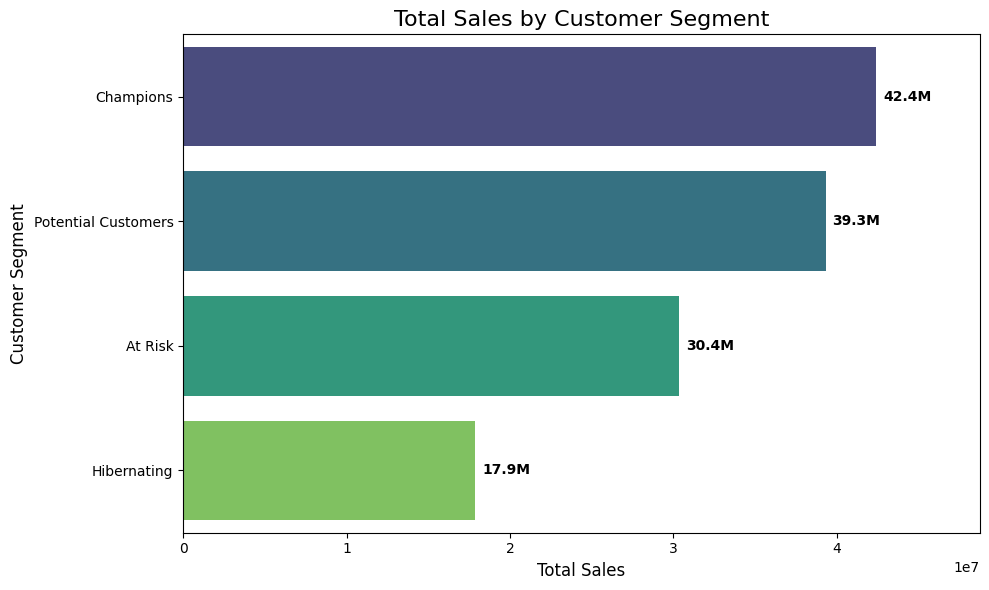

In [ ]:
#visualize revenue segment
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Sales_Total', y='Customer_Segment', data=revenue_segment, palette='viridis')

# Menambahkan data label dengan format M (Millions)
for p in ax.patches:
    width = p.get_width()
    if width > 0:  # Memastikan bar memiliki nilai
        ax.annotate(f'{width/1e6:.1f}M',
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(5, 0),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.title('Total Sales by Customer Segment', fontsize=16)
plt.xlabel('Total Sales', fontsize=12)
plt.ylabel('Customer Segment', fontsize=12)

# Memberi ruang ekstra di sisi kanan agar label tidak terpotong
plt.xlim(0, revenue_segment['Sales_Total'].max() * 1.15)

plt.tight_layout()
plt.show()

**Business Insights**

* Mayoritas pendapatan bertumpu pada 2 segmen atas (Champions & Potential Customers) yang menyumbang lebih dari 81.7M (sekitar $62\%$ dari total revenue). Ini menunjukkan bahwa kesehatan finansial perusahaan sangat bergantung pada performa kedua segmen ini.

* Kontribusi sebesar 30.4M dari segmen At Risk menandakan ada aset pendapatan yang sangat besar yang terancam hilang jika pelanggan dalam kategori ini tidak segera ditangani (churn).

* Kontribusi 17.9M dari segmen Hibernating menunjukkan bahwa kelompok pelanggan ini memiliki frekuensi dan nilai transaksi yang paling pasif.

**Analysis of Business Implications**

* Champions adalah pendorong utama pendapatan dengan kombinasi frekuensi belanja tinggi dan nilai transaksi besar.

* Potential Customers memiliki potensi besar untuk dikonversi menjadi Champions jika dipicu oleh promosi yang tepat (seperti cross-selling atau peningkatan nilai keranjang belanja/up-selling).

* Pelanggan di segmen At Risk dulunya rutin belanja atau mengeluarkan uang dalam jumlah besar, namun belakangan ini jarang bertransaksi. Kehilangan segmen ini secara permanen akan berdampak signifikan pada penurunan revenue perusahaan sebesar puluhan juta dolar.

* Mengalokasikan anggaran promosi yang besar ke segmen Hibernating cenderung menghasilkan Return on Investment (ROI) yang rendah dibanding mengalokasikannya untuk mempertahankan Champions atau mereaktivasi At Risk.

## 2. Segmen mana yang paling besar berdasarkan jumlah pelanggannya?


In [ ]:
#unique Customer_ID and their segment
unique_customers = data_usa[['Customer_ID', 'Customer_Segment']].drop_duplicates()

#count number of customers per segment
total_customer_segment = unique_customers['Customer_Segment'].value_counts().reset_index()
total_customer_segment.columns = ['Customer_Segment', 'Total_Customers']
total_customer_segment

,Customer_Segment,Total_Customers
0,Hibernating,33676
1,At Risk,10454
2,Potential Customers,9792
3,Champions,4036


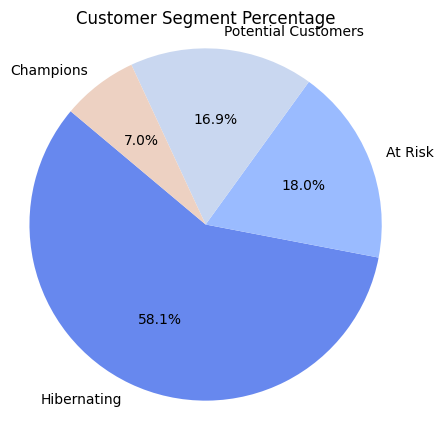

In [ ]:
#visualize total customers segment
plt.figure(figsize = (5,5))
plt.pie(total_customer_segment['Total_Customers'],
        labels = total_customer_segment['Customer_Segment'],
        autopct = '%1.1f%%',
        startangle = 140,
        colors = sns.color_palette('coolwarm'))
plt.title('Customer Segment Percentage')
plt.axis('equal')
plt.show()

**Business Insights**

* Segmen Hibernating merupakan kelompok terbesar dengan jumlah 33.676 pelanggan (sekitar 58% dari total populasi pelanggan). Ini menunjukkan bahwa lebih dari separuh basis pelanggan perusahaan saat ini berada dalam kondisi tidak aktif atau jarang bertransaksi.

* Meskipun segmen Champions memiliki jumlah pelanggan terkecil yaitu 4.036 pelanggan ($~7\%$), segmen ini terbukti menghasilkan penjualan sebesar 42.4M (penjualan tertinggi). Ini menegaskan prinsip Pareto ($80/20$), di mana porsi kecil pelanggan menghasilkan porsi kontribusi terbesar.

* Gabungan segmen At Risk ($10.454$) dan Potential Customers ($9.792$) mencapai 20.246 pelanggan ($~35\%$). Kedua kelompok ini mewakili basis pelanggan yang bernilai tinggi namun membutuhkan perlakuan khusus agar tidak hilang secara permanen.

**Analysis of Business Implications**

* Setiap individu di segmen Champions memiliki nilai Customer Lifetime Value (CLV) yang sangat tinggi. Kehilangan 1% saja dari segmen ini akan berdampak secara finansial jauh lebih signifikan dibandingkan kehilangan pelanggan dari segmen Hibernating.

* Dilihat dari kuantitasnya ($10.454$ pelanggan), segmen At Risk menyumbang penjualan sebesar 30.4M. Ini adalah area rentan (high risk of churn) di mana pelanggan dengan pengeluaran besar/frekuensi tinggi mulai berhenti berbelanja. Tanpa program reaktivasi (win-back strategy), potensi kehilangan revenue puluhan juta sangat nyata.

* Segmen Potential Customers dengan $9.792$ pelanggan yang aktif dan sudah memberikan sales 39.3M, segmen ini adalah prioritas utama untuk didorong (upsell/cross-sell) agar bertransaksi lebih sering atau membeli produk bernilai lebih tinggi sehingga bisa berpindah ke segmen Champions.

* Mengingat jumlahnya yang sangat dominan ($33.676$), melakukan promosi/iklan berbayar massal (paid campaigns) ke segmen Hibernating akan sangat tidak efisien dan menghamburkan anggaran. Fokus untuk segmen ini cukup menggunakan automated/low-cost channels.

## 3. Segmen mana yang memiliki frekuensi transaksi tertinggi?

In [ ]:
#frequency total per segment
# Menhitung rata-rata frekuensi per pelanggan pada data_usa
avg_freq_usa = data_usa.groupby('Customer_Segment')['Frequency'].mean().reset_index()
avg_freq_usa = avg_freq_usa.rename(columns={'Frequency': 'Avg_Frequency'})
avg_freq_usa = avg_freq_usa.sort_values(by='Avg_Frequency', ascending=False)

avg_freq_usa

,Customer_Segment,Avg_Frequency
1,Champions,3.636963
3,Potential Customers,2.341139
0,At Risk,2.020130
2,Hibernating,1.396305


/tmp/ipykernel_1179/101003504.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=avg_freq_usa, x='Avg_Frequency', y='Customer_Segment', palette='Blues_d')


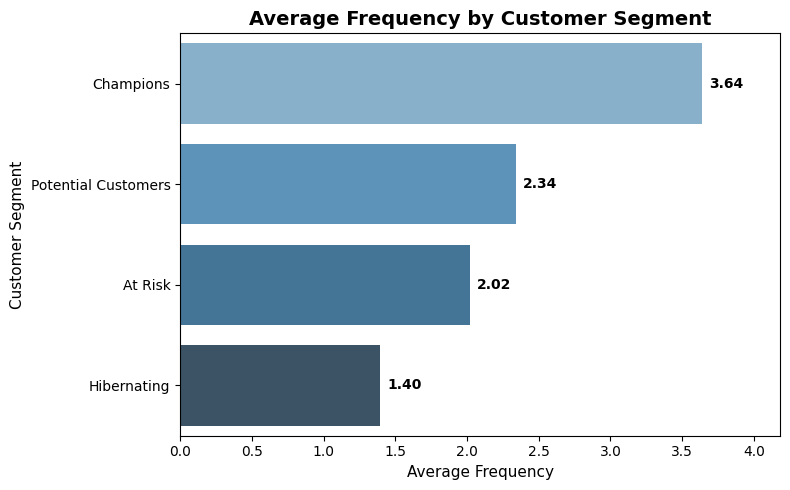

In [ ]:
# Visualization of Average Frequency
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=avg_freq_usa, x='Avg_Frequency', y='Customer_Segment', palette='Blues_d')

# Menambahkan label angka desimal di ujung setiap bar
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{width:.2f}',
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(5, 0),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.title('Average Frequency by Customer Segment', fontsize=14, fontweight='bold')
plt.xlabel('Average Frequency', fontsize=11)
plt.ylabel('Customer Segment', fontsize=11)

# Memberikan ruang ekstra di sebelah kanan agar label angka tidak terpotong
plt.xlim(0, avg_freq_usa['Avg_Frequency'].max() * 1.15)

plt.tight_layout()
plt.show()

**Business Insights**

* Pelanggan di segmen Champions memiliki rata-rata frekuensi belanja tertinggi, yaitu 3,64 kali per pelanggan. Ini menunjukkan bahwa segmen ini memiliki tingkat aktivitas dan keterikatan (engagement) yang jauh lebih tinggi dibandingkan kelompok pelanggan lainnya.

* Segmen Potential Customers dan At Risk menunjukkan tingkat frekuensi transaksi yang berdekatan, masing-masing sebesar 2,34 kali dan 2,02 kali per pelanggan. Pelanggan Potential Customers berada pada alur yang tepat untuk ditingkatkan frekuensinya. Pelanggan At Risk sebelumnya bertransaksi rata-rata 2 kali, namun saat ini dalam kondisi berisiko lepas (churn).

* Segmen Hibernating mencatatkan rata-rata frekuensi belanja terendah, yaitu hanya 1,40 kali per pelanggan, yang mengindikasikan bahwa mayoritas pelanggan di segmen ini cenderung hanya melakukan transaksi tunggal (one-time buyers).

**Analysis of Business Implications**

* Rata-rata frekuensi $~3,64$ kali membuktikan bahwa Champions memiliki kebiasaan belanja yang sudah terbentuk (habitual buying). Menjaga kepuasan dan konsistensi pengalaman bertransaksi kelompok ini sangat penting agar frekuensi belanja mereka tidak mengalami penurunan.

* Dengan rata-rata frekuensi $2,34$ kali, segmen Potential Customers sudah melewati ambang batas pembeli pertama (first-time buyer). Memberikan dorongan insentif (seperti program loyalty points atau kupon belanja berikutnya) dapat memicu peningkatan frekuensi ke tingkat Champions ($\ge 3,6$ kali).

* Angka $2,02$ kali menunjukkan pelanggan At Risk sebenarnya pernah melakukan repeat purchase, namun kini frekuensinya terhenti. Jika tidak ada penanganan, mereka akan bergeser ke segmen Hibernating.

* Angka $1,40$ kali pada segmen Hibernating menandakan sebagian besar alokasi biaya pemasaran untuk kelompok ini berisiko menjadi tidak efisien (low ROI). Perusahaan perlu menerapkan strategi otomatisasi re-engagement yang berbiaya rendah (seperti email remarketing atau push notifications) daripada kampanye promosi agresif, guna mengidentifikasi pelanggan yang masih bisa diaktifkan kembali tanpa membuang anggaran.

## 3. Bagaimana tren segmen pelanggan dari waktu ke waktu, apakah ada perubahan dari bulan ke bulan?

In [ ]:
#extract Month-Year from your date column
data_usa['Month'] = pd.to_datetime(data_usa['Date']).dt.to_period('M').astype(str)

monthly_segment_trend = data_usa.groupby(['Month', 'Customer_Segment'])['Customer_ID'].nunique().reset_index()
monthly_segment_trend = monthly_segment_trend.rename(columns={'Customer_ID': 'Customer_Count'})
monthly_segment_trend

,Month,Customer_Segment,Customer_Count
0,2023-03,At Risk,2070
1,2023-03,Champions,1019
2,2023-03,Hibernating,3518
3,2023-03,Potential Customers,975
4,2023-04,At Risk,1968
5,2023-04,Champions,1000
6,2023-04,Hibernating,3450
7,2023-04,Potential Customers,970
8,2023-05,At Risk,1987
9,2023-05,Champions,977


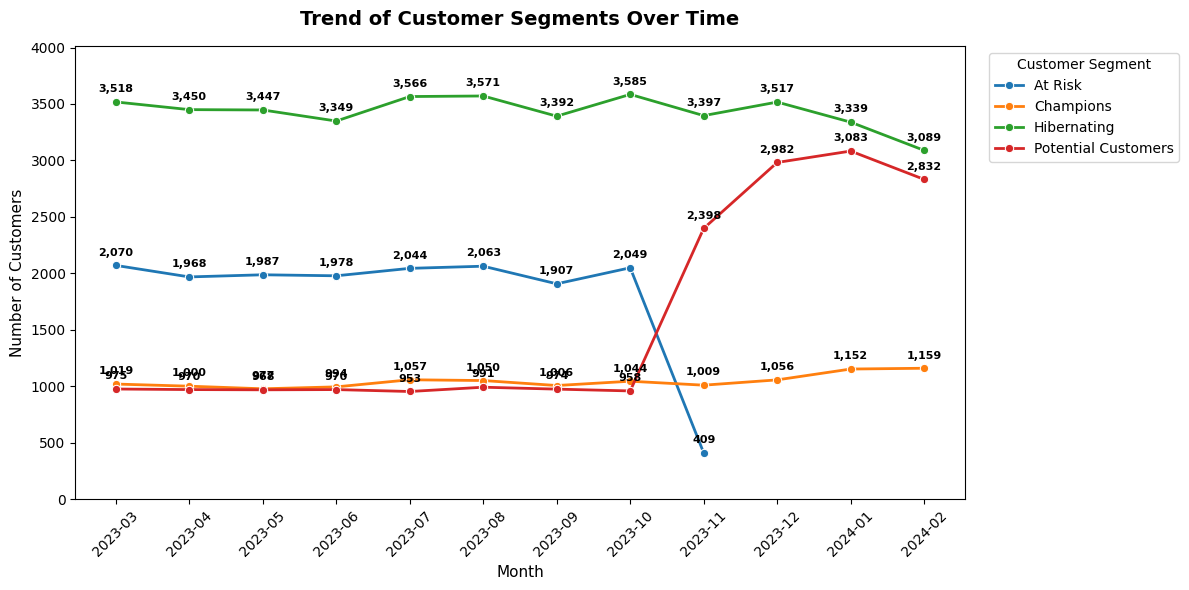

In [ ]:
# visualize customer segment over time
plt.figure(figsize=(12, 6))
ax = sns.lineplot(
    data=monthly_segment_trend,
    x='Month', y='Customer_Count', hue='Customer_Segment',
    marker='o', linewidth=2
)

# Menambahkan data label angka pada setiap titik garis
for line in ax.lines:
    x_data = line.get_xdata()
    y_data = line.get_ydata()
    for x, y in zip(x_data, y_data):
        if not np.isnan(y):
            ax.annotate(
                f'{int(y):,}',
                (x, y),
                textcoords="offset points",
                xytext=(0, 7),
                ha='center',
                fontsize=8,
                fontweight='bold'
            )

plt.title('Trend of Customer Segments Over Time', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=11)
plt.ylabel('Number of Customers', fontsize=11)
plt.xticks(rotation=45)

# Posisikan legenda di luar kanan atas
plt.legend(title='Customer Segment', bbox_to_anchor=(1.02, 1), loc='upper left')

# Beri ruang ekstra di bagian atas sumbu Y agar label angka titik tertinggi tidak terpotong
plt.ylim(0, monthly_segment_trend['Customer_Count'].max() * 1.12)

plt.tight_layout()
plt.show()

**Business Insights**

* Segmen At Risk yang stabil di angka 2.000 pelanggan melonjak turun ke titik terendah 409 pada Nov 2023. Secara bersamaan, segmen Potential Customers melonjak dari 958 (Okt 2023) hingga puncaknya 3.083 (Jan 2024). Ini mengindikasikan adanya campaign reaktivasi atau akuisisi baru yang sangat efektif pada akhir tahun.   

* Hibernating menjadi kelompok terbesar di sepanjang periode, dimulai dari 3.518 (Mar 2023) hingga puncaknya 3.585 (Okt 2023). Meskipun turun perlahan ke 3,089 di Feb 2024, segmen ini masih mendominasi porsi pelanggan yang mengindikasikan tingginya retensi pasif/dormant user.

* Segmen Champions berada di kisaran terendah (1.000 pelanggan) namun menunjukkan pertumbuhan konsisten dari 1.009 (Nov 2023) naik hingga 1.159 pelanggan (Feb 2024). Hal ini menunjukkan adanya konversi positif pelanggan loyal dari waktu ke waktu.   

**Analysis of Business Implications**

* Lonjakan Potential Customers yang mencapai angka 2.800–3.000 pelanggan di awal 2024 merupakan aset pertumbuhan utama. Fokus strategi upselling dan cross-selling pada kelompok ini berpotensi besar mengonversi mereka menjadi pelanggan loyal (Champions).   


* Penurunan tajam segmen At Risk pada akhir 2023 membuktikan bahwa retensi aktif dapat mencegah churn permanen. Namun, tren ini harus terus dijaga agar pelanggan tidak kembali merosot ke status At Risk di kuartal berikutnya.   

* Peningkatan bertahap pada segmen Champions (+150 pelanggan dalam 3 bulan terakhir) berdampak langsung pada stabilitas Customer Lifetime Value (LTV). Perlindungan terhadap segmen ini melalui program loyalitas VIP sangat krusial untuk menjaga pendapatan inti.   

* Dengan jumlah segmen Hibernating yang masih berada di kisaran >3.000 pelanggan, melakukan paid campaign secara massal akan sangat tidak efisien. Pemanfaatan saluran berbiaya rendah (automated email marketing/push notifications) lebih disarankan untuk menyaring kembali pelanggan yang masih berpotensi aktif.

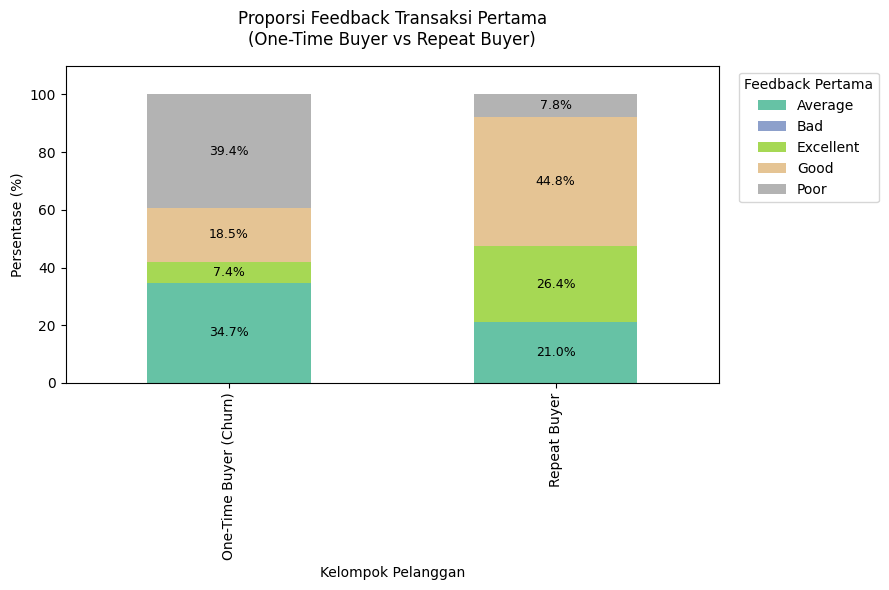

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Hitung proporsi persentase feedback pada transaksi pertama
feedback_first_trx = (
    pd.crosstab(
        first_transactions['Customer_Group'],
        first_transactions['Feedback'],
        normalize='index',
    )
    * 100
)

# 2. Buat plot stacked bar chart
fig, ax = plt.subplots(figsize=(9, 6))
feedback_first_trx.plot(kind='bar', stacked=True, ax=ax, colormap='Set2')

# 3. Tambahkan label angka persentase di dalam setiap segmen batang
for container in ax.containers:
  labels = [
      f'{v.get_height():.1f}%' if v.get_height() > 3 else '' for v in container
  ]
  ax.bar_label(container, labels=labels, label_type='center', fontsize=9)

# 4. Pengaturan judul dan sumbu
ax.set_title(
    'Proporsi Feedback Transaksi Pertama\n(One-Time Buyer vs Repeat Buyer)',
    fontsize=12,
    pad=15,
)
ax.set_xlabel('Kelompok Pelanggan', fontsize=10)
ax.set_ylabel('Persentase (%)', fontsize=10)
ax.set_ylim(0, 110)  # Memberi ruang untuk legend
ax.legend(title='Feedback Pertama', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
from scipy import stats

# ------------------------------------------------------------------------------
# 1. Uji Mann-Whitney U (Perbedaan Rating Transaksi Pertama)
# ------------------------------------------------------------------------------
ratings_churn = first_transactions[
    first_transactions['Customer_Group'] == 'One-Time Buyer (Churn)'
]['Ratings'].dropna()

ratings_repeat = first_transactions[
    first_transactions['Customer_Group'] == 'Repeat Buyer'
]['Ratings'].dropna()

u_stat, p_val_mwu = stats.mannwhitneyu(ratings_churn, ratings_repeat)
print(f'Mann-Whitney U Test p-value: {p_val_mwu:.5f}')

if p_val_mwu < 0.05:
  print(
      '-> Signifikan: Terdapat perbedaan rating transaksi pertama yang nyata'
      ' antara pelanggan Churn dan Repeat Buyer.'
  )
else:
  print(
      '-> Tidak Signifikan: Tidak ada perbedaan rating transaksi pertama yang'
      ' nyata antara kedua kelompok.'
  )


# ------------------------------------------------------------------------------
# 2. Uji Chi-Square (Hubungan Kategori Feedback Pertama vs Status Churn)
# ------------------------------------------------------------------------------
contingency_table = pd.crosstab(
    first_transactions['Customer_Group'], first_transactions['Feedback']
)

chi2, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)
print(f'\nChi-Square Test p-value: {p_val_chi2:.5f}')

if p_val_chi2 < 0.05:
  print(
      '-> Signifikan: Terdapat hubungan nyata antara kategori Feedback pertama'
      ' dengan keputusan pelanggan untuk Churn.'
  )
else:
  print(
      '-> Tidak Signifikan: Feedback transaksi pertama tidak berhubungan secara'
      ' signifikan dengan keputusan Churn.'
  )

Mann-Whitney U Test p-value: 0.00000
-> Signifikan: Terdapat perbedaan rating transaksi pertama yang nyata antara pelanggan Churn dan Repeat Buyer.

Chi-Square Test p-value: 0.00000
-> Signifikan: Terdapat hubungan nyata antara kategori Feedback pertama dengan keputusan pelanggan untuk Churn.


**Kesimpulan:**

* Hipotesis Terbukti (First Experience Drives Retention): Pengalaman pada transaksi pertama merupakan faktor penentu utama (critical touchpoint) yang memicu churn. Kegagalan layanan atau ketidakpuasan pelanggan di awal transaksi berdampak langsung terhadap keputusan pelanggan untuk menghentikan interaksi dengan platform.

* Dampak One-Time Buyers Terhadap Anggaran Pemasaran: Banyaknya one-time buyers yang dipicu oleh pengalaman pertama yang buruk mengakibatkan biaya akuisisi pelanggan (Customer Acquisition Cost / CAC) menjadi tidak efisien, karena perusahaan gagal mengonversi pelanggan baru menjadi pelanggan berulang (Repeat Customers).

# **Summary Insights**

* Champions merupakan segmen paling bernilai yang menyumbang pendapatan terbesar (42.4M) dengan rata-rata frekuensi belanja tertinggi (3,64 kali/pelanggan), meskipun jumlah pelanggannya paling sedikit (4.036 pelanggan / $\approx 7\%$).

* Potential Customers berada di urutan kedua penyumbang penjualan sebesar 39.3M (9.792 pelanggan), memiliki frekuensi transaksi yang menjanjikan (2,34 kali/pelanggan).

* Gabungan segmen Champions dan Potential Customers menyumbang lebih dari 81.7M ($\approx 62\%$) dari total revenue perusahaan.

* Segmen At Risk menyumbang penjualan signifikan sebesar 30.4M dari 10.454 pelanggan. Kelompok ini mencatatkan rata-rata frekuensi belanja 2,02 kali, namun menunjukkan tanda-tanda berhenti bertransaksi (churn risk) karena nilai Recency yang rendah ($R \le 2$).

* Segmen Hibernating mendominasi secara kuantitas (33.676 pelanggan / $\approx 58\%$), namun hanya menyumbang penjualan 17.9M dengan frekuensi transaksi terendah (1,40 kali/pelanggan). Sebagian besar pelanggan di segmen ini cenderung hanya menjadi pembeli satu kali (one-time buyers).

* Fluktuasi bulanan menunjukkan adanya peningkatan jumlah pelanggan di segmen Potential Customers dan Champions pada periode tertentu (seperti awal 2024), serta pergeseran yang perlu diintervensi pada segmen At Risk agar tidak terus merosot ke segmen Hibernating.



# **Actionable Recommendations**

**Champions** (Menjaga retensi dan mencegah kepindahan pelanggan berharga tinggi.)

* Buat program VIP Loyalty / Exclusivity (akses awal ke produk baru, priority customer service, dan bonus poin tanpa syarat yang rumit).

* Hindari diskon harga secara masif; fokus pada brand appreciation, hadiah ulang tahun, dan penawaran terpersonalisasi.

**Potential Customers** (Meningkatkan frekuensi belanja dari $\approx 2,3$ kali menuju $\ge 3,6$ kali agar terkonversi menjadi Champions.)

* Penerapan Personalized Cross-Selling & Upselling berdasarkan riwayat transaksi.

* Berikan penawaran berbasis Threshold Bonus (misal: "Tambah $15 lagi untuk mendapatkan voucher potongan belanja berikutnya").

**At Risk** (Mencegah terjadinya churn permanen dan menyelamatkan potensi revenue sebesar 30.4M.)

* Jalankan kampanye Win-Back Push Notification & Email Marketing secara otomatis dengan pesan "We Miss You" disertai kupon diskon berbatas waktu (limited-time urge).

* Kirimkan survei kepuasan pelanggan (NPS/Feedback survey) untuk mengidentifikasi penyebab penurunan aktivitas belanja.

**Hibernating** (Efisiensi anggaran pemasaran dan pembersihan basis data pelanggan.)

* Hentikan Paid Campaign / Iklan Berbayar secara massal ke segmen ini untuk menghindari pembengkakan Customer Acquisition Cost (CAC).

* Manfaatkan Automated Email Blast berbiaya rendah dengan penawaran Clearance Sale atau promo produk pemicu (hook product). Jika tidak ada respons dalam periode tertentu, pertimbangkan untuk menonaktifkan kontak dari daftar kampanye utama.



# Download Clean File

In [ ]:
#dowload data_usa
data_usa.to_csv('data_usa.csv', index=False)
from google.colab import files
files.download('data_usa.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>